# Proyecto 01: Retail Intelligence (RetailVenture C.A.)
## A4: Evaluación de Marketing, Conversión, Elasticidad de Descuentos y Retorno de Inversión

**Autores:** Daniel, Andrés y Samuel (Grupo 3)  
**Materia:** Tópicos Especiales para la Gestión de Datos · UCAB  
**Profesor:** Armen Djenanian  

---

### Preguntas de Investigación y Objetivos del Análisis
La gerencia general de **RetailVenture C.A.** reporta una **pérdida de efectividad publicitaria**, señalando una reducción de la tasa de conversión en los últimos 18 meses (del 22% al 11% en el relato ejecutivo). 

En esta actividad se formulan y responden rigurosamente las siguientes preguntas de investigación con base en los microdatos empíricos:
1. **A4.1:** ¿Cuál es la tasa real de conversión publicitaria por canal, tipo de campaña y segmento, y cómo evolucionó temporalmente? ¿Qué brecha existe entre la conversión declarada en marketing y la compra validada a 30 días?
2. **A4.2:** ¿Existe evidencia de que mayores descuentos aumenten sistemáticamente la conversión, o se observan rendimientos decrecientes o estancamiento en niveles superiores al 20%?
3. **A4.3:** ¿Se asocia la no conversión a fricciones operativas de post-venta (quejas en CRM o devoluciones), o existen explicaciones alternativas fundamentadas en datos?
4. **A4.4:** Bajo una atribución Last-Touch estricta a 30 días (sin compras duplicadas), ¿cuál es el retorno bruto contable frente al **ROI incremental real** evaluado mediante remuestreo bootstrap e inferencia contrafactual?
5. **Resumen Ejecutivo:** Tabla consolidada de métricas maestras de marketing gobernadas por variables dinámicas para su consumo en el dashboard gerencial A5.


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint

# Configuración visual ejecutiva
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Directorio de datos limpios
DATA_PATH = Path("../data/clean")

# Carga de datasets limpios
campanas = pd.read_csv(DATA_PATH / "campanas_limpia.csv", parse_dates=["fecha_envio"])
transacciones = pd.read_csv(DATA_PATH / "transacciones_maestra.csv", parse_dates=["fecha"])
clientes = pd.read_csv(DATA_PATH / "clientes_maestra.csv")
crm = pd.read_csv(DATA_PATH / "crm_limpio.csv", parse_dates=["fecha"])

print(f"Campañas cargadas: {len(campanas):,}")
print(f"Transacciones operativas: {len(transacciones):,}")
print(f"Clientes maestros: {len(clientes):,}")
print(f"Interacciones CRM: {len(crm):,}")


Campañas cargadas: 8,820
Transacciones operativas: 50,000
Clientes maestros: 8,000
Interacciones CRM: 4,684


---
## A4.1 Medición Multidimensional de Conversión, Calidad del Flag y Evolución Temporal

Auditamos la efectividad publicitaria distinguiendo formalmente:
- **Conversión Declarada (`convertido`):** Flag auto-reportado por el sistema de marketing.
- **Conversión Validada (`convertido_validado_30d`):** Registro auditable de si el cliente ejecutó al menos una compra en la ventana de 30 días posteriores al envío.


In [2]:
# 1. Auditoría de Calidad del Flag Declarado (C5)
# Evaluamos si estar marcado como 'convertido=1' predice efectivamente compras en 30 días
camp_elegible_all = campanas[campanas['fecha_envio'] < '2024-12-01'].copy()
tx_por_cliente_fechas = {cli: g['fecha'].values for cli, g in transacciones.groupby('cliente_id')}

compro_en_30d = []
for _, r in camp_elegible_all.iterrows():
    f0 = np.datetime64(r['fecha_envio'])
    f1 = np.datetime64(r['fecha_envio'] + pd.Timedelta(days=30))
    tx = tx_por_cliente_fechas.get(r['cliente_id'])
    compro_en_30d.append(np.any((tx >= f0) & (tx <= f1)) if tx is not None else False)

camp_elegible_all['compro_real_30d'] = compro_en_30d

p_compra_conv1 = camp_elegible_all.loc[camp_elegible_all['convertido'] == 1, 'compro_real_30d'].mean() * 100
p_compra_conv0 = camp_elegible_all.loc[camp_elegible_all['convertido'] == 0, 'compro_real_30d'].mean() * 100
n_conv_decl = (camp_elegible_all['convertido'] == 1).sum()
n_conv_con_compra = (camp_elegible_all['convertido'] == 1 & camp_elegible_all['compro_real_30d']).sum()

print("--- AUDITORÍA DE CONFIABILIDAD DEL FLAG 'convertido' (C5) ---")
print(f"• P(Compra real en 30d | convertido = 1): {p_compra_conv1:.2f}% (N={n_conv_decl:,} campañas declaradas)")
print(f"• P(Compra real en 30d | convertido = 0): {p_compra_conv0:.2f}% (N={len(camp_elegible_all)-n_conv_decl:,} campañas no declaradas)")
print(f"• Diferencia de probabilidad: {p_compra_conv1 - p_compra_conv0:+.2f} p.p.")
print(f"• Hallazgo metodológico: El flag declarado solo incrementa en {p_compra_conv1 - p_compra_conv0:.2f} p.p. la probabilidad de compra real")
print(f"  frente al ritmo base de clientes sin conversión declarada ({p_compra_conv0:.2f}%).")


--- AUDITORÍA DE CONFIABILIDAD DEL FLAG 'convertido' (C5) ---
• P(Compra real en 30d | convertido = 1): 22.81% (N=776 campañas declaradas)
• P(Compra real en 30d | convertido = 0): 20.45% (N=7,674 campañas no declaradas)
• Diferencia de probabilidad: +2.36 p.p.
• Hallazgo metodológico: El flag declarado solo incrementa en 2.36 p.p. la probabilidad de compra real
  frente al ritmo base de clientes sin conversión declarada (20.45%).


In [3]:
# 2. Conversión por Tipo de Campaña y Segmento (Declarada vs Validada)
conv_tipo = campanas.groupby('tipo_campana').agg(
    envios=('campana_id', 'count'),
    conv_declarada=('convertido', 'sum'),
    tasa_declarada=('convertido', lambda s: s.mean() * 100),
    conv_validada=('convertido_validado_30d', 'sum'),
    tasa_validada=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_medio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('tasa_declarada', ascending=False)

print("CONVERSIÓN POR TIPO DE CAMPAÑA:")
display(conv_tipo.round(2))

conv_seg = campanas.groupby('segmento').agg(
    envios=('campana_id', 'count'),
    conv_declarada=('convertido', 'sum'),
    tasa_declarada=('convertido', lambda s: s.mean() * 100),
    conv_validada=('convertido_validado_30d', 'sum'),
    tasa_validada=('convertido_validado_30d', lambda s: s.mean() * 100),
    descuento_medio=('descuento_ofrecido', lambda s: s.mean() * 100)
).reset_index().sort_values('tasa_declarada', ascending=False)

print("\nCONVERSIÓN POR SEGMENTO DE CLIENTE:")
display(conv_seg.round(2))


CONVERSIÓN POR TIPO DE CAMPAÑA:


,tipo_campana,envios,conv_declarada,tasa_declarada,conv_validada,tasa_validada,descuento_medio
1,email_fidelizacion,1748,174,9.95,43,2.46,12.59
2,push_reactivacion,1768,162,9.16,34,1.92,12.31
0,email_descuento,3099,274,8.84,67,2.16,12.48
4,social_ads,860,75,8.72,13,1.51,12.52
3,sms_oferta_flash,1345,112,8.33,22,1.64,12.19



CONVERSIÓN POR SEGMENTO DE CLIENTE:


,segmento,envios,conv_declarada,tasa_declarada,conv_validada,tasa_validada,descuento_medio
4,Premium,877,120,13.68,65,7.41,12.64
3,Nuevo,933,99,10.61,4,0.43,12.25
0,Esporádico,3118,297,9.53,32,1.03,12.50
1,Frecuente,2654,213,8.03,76,2.86,12.38
2,Inactivo,1238,68,5.49,2,0.16,12.34


In [4]:
# 3. Combinaciones Clave (Tipo x Canal x Segmento) con Mínimo 100 Envíos e IC Wilson (R7 / C15)
comb = campanas.groupby(['tipo_campana', 'canal_campana', 'segmento']).agg(
    envios=('campana_id', 'count'),
    conv_decl=('convertido', 'sum'),
    conv_val=('convertido_validado_30d', 'sum')
).reset_index()

comb_100 = comb[comb['envios'] >= 100].copy()
comb_100['tasa_declarada'] = (comb_100['conv_decl'] / comb_100['envios']) * 100
comb_100['tasa_validada'] = (comb_100['conv_val'] / comb_100['envios']) * 100

ci_decl = [proportion_confint(k, n, alpha=0.05, method='wilson') for k, n in zip(comb_100['conv_decl'], comb_100['envios'])]
ci_val = [proportion_confint(k, n, alpha=0.05, method='wilson') for k, n in zip(comb_100['conv_val'], comb_100['envios'])]

comb_100['ic_95_declarada'] = [f"[{l*100:.1f}%, {u*100:.1f}%]" for l, u in ci_decl]
comb_100['ic_95_validada'] = [f"[{l*100:.1f}%, {u*100:.1f}%]" for l, u in ci_val]

comb_100 = comb_100.sort_values('tasa_declarada', ascending=False)

print(f"COMBINACIONES CON >= 100 ENVÍOS ({len(comb_100)} combinaciones elegibles de {len(comb)} totales):")
display(comb_100[['tipo_campana', 'canal_campana', 'segmento', 'envios', 
                  'tasa_declarada', 'ic_95_declarada', 'tasa_validada', 'ic_95_validada']].round(2))

# Resaltar la fuga en segmentos Nuevo e Inactivo
envios_nuevo_inactivo = campanas[campanas['segmento'].isin(['Nuevo', 'Inactivo'])].shape[0]
pct_nuevo_inactivo = (envios_nuevo_inactivo / len(campanas)) * 100
val_nuevo = conv_seg.loc[conv_seg['segmento']=='Nuevo', 'tasa_validada'].values[0]
val_inactivo = conv_seg.loc[conv_seg['segmento']=='Inactivo', 'tasa_validada'].values[0]

print(f"\n• Auditoría de Eficiencia de Segmentación:")
print(f"  Los segmentos 'Nuevo' e 'Inactivo' recibieron {envios_nuevo_inactivo:,} envíos ({pct_nuevo_inactivo:.1f}% de la pauta total),")
print(f"  alcanzando tasas de conversión validadas de apenas {val_nuevo:.2f}% y {val_inactivo:.2f}%, respectivamente.")
print(f"  Hipótesis respaldada por datos: Gran parte del presupuesto publicitario se asigna a contactos fríos o desconectados")
print(f"  donde el incentivo digital no se materializa en compras operativas.")


COMBINACIONES CON >= 100 ENVÍOS (24 combinaciones elegibles de 25 totales):


,tipo_campana,canal_campana,segmento,envios,tasa_declarada,ic_95_declarada,tasa_validada,ic_95_validada
9,email_fidelizacion,email,Premium,166,15.66,"[10.9%, 22.0%]",9.04,"[5.6%, 14.4%]"
14,push_reactivacion,push_app,Premium,189,15.34,"[10.9%, 21.2%]",6.88,"[4.1%, 11.4%]"
23,social_ads,redes_sociales,Nuevo,100,13.00,"[7.8%, 21.0%]",0.00,"[0.0%, 3.7%]"
4,email_descuento,email,Premium,321,12.77,"[9.6%, 16.9%]",8.41,"[5.8%, 12.0%]"
8,email_fidelizacion,email,Nuevo,181,11.60,"[7.7%, 17.1%]",0.00,"[0.0%, 2.1%]"
18,sms_oferta_flash,sms,Nuevo,153,11.11,"[7.1%, 17.1%]",0.00,"[0.0%, 2.4%]"
13,push_reactivacion,push_app,Nuevo,165,10.91,"[7.0%, 16.6%]",0.61,"[0.1%, 3.4%]"
5,email_fidelizacion,email,Esporádico,619,10.18,"[8.0%, 12.8%]",0.97,"[0.4%, 2.1%]"
0,email_descuento,email,Esporádico,1084,9.87,"[8.2%, 11.8%]",1.11,"[0.6%, 1.9%]"
15,sms_oferta_flash,sms,Esporádico,474,9.49,"[7.2%, 12.5%]",1.27,"[0.6%, 2.7%]"



• Auditoría de Eficiencia de Segmentación:
  Los segmentos 'Nuevo' e 'Inactivo' recibieron 2,171 envíos (24.6% de la pauta total),
  alcanzando tasas de conversión validadas de apenas 0.43% y 0.16%, respectivamente.
  Hipótesis respaldada por datos: Gran parte del presupuesto publicitario se asigna a contactos fríos o desconectados
  donde el incentivo digital no se materializa en compras operativas.


In [5]:
# 4. Tendencia Temporal Semestral y Trimestral (C5)
campanas['anio_trimestre'] = campanas['fecha_envio'].dt.to_period('Q').astype(str)
campanas['semestre'] = campanas['fecha_envio'].dt.year.astype(str) + '-S' + ((campanas['fecha_envio'].dt.month - 1) // 6 + 1).astype(str)

conv_sem = campanas.groupby('semestre').agg(
    total_envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100)
).reset_index()

conv_trim = campanas.groupby('anio_trimestre').agg(
    total_envios=('campana_id', 'count'),
    conv_declarada_pct=('convertido', lambda s: s.mean() * 100),
    conv_validada_pct=('convertido_validado_30d', lambda s: s.mean() * 100)
).reset_index()

print("EVOLUCIÓN TEMPORAL SEMESTRAL:")
display(conv_sem.round(2))

print("\nEVOLUCIÓN TEMPORAL TRIMESTRAL:")
display(conv_trim.round(2))

# Comparación honesta con el brief
decl_s1 = conv_sem.loc[conv_sem['semestre']=='2023-S1', 'conv_declarada_pct'].values[0]
decl_s4 = conv_sem.loc[conv_sem['semestre']=='2024-S2', 'conv_declarada_pct'].values[0]
caida_relativa = ((decl_s4 - decl_s1) / decl_s1) * 100

print(f"\n• Contraste Científico con el Brief Ejecutivo:")
print(f"  El relato ejecutivo señalaba una caída 'del 22% al 11%'.")
print(f"  Los microdatos muestran que la conversión declarada partió de {decl_s1:.1f}% en 2023-S1 y descendió a {decl_s4:.1f}% en 2024-S2.")
print(f"  Conclusión: Aunque los niveles absolutos difieren (nunca alcanzaron el 22%), la magnitud de la caída relativa ({caida_relativa:.1f}%)")
print(f"  confirma de manera precisa una contracción de efectividad de aproximadamente el 50%.")


EVOLUCIÓN TEMPORAL SEMESTRAL:


,semestre,total_envios,conv_declarada_pct,conv_validada_pct
0,2023-S1,2168,11.81,2.91
1,2023-S2,2200,10.68,2.09
2,2024-S1,2210,7.38,1.86
3,2024-S2,2242,6.38,1.29



EVOLUCIÓN TEMPORAL TRIMESTRAL:


,anio_trimestre,total_envios,conv_declarada_pct,conv_validada_pct
0,2023Q1,1055,11.28,3.13
1,2023Q2,1113,12.31,2.70
2,2023Q3,1094,11.15,2.29
3,2023Q4,1106,10.22,1.90
4,2024Q1,1082,7.95,1.85
5,2024Q2,1128,6.83,1.86
6,2024Q3,1167,7.11,1.63
7,2024Q4,1075,5.58,0.93



• Contraste Científico con el Brief Ejecutivo:
  El relato ejecutivo señalaba una caída 'del 22% al 11%'.
  Los microdatos muestran que la conversión declarada partió de 11.8% en 2023-S1 y descendió a 6.4% en 2024-S2.
  Conclusión: Aunque los niveles absolutos difieren (nunca alcanzaron el 22%), la magnitud de la caída relativa (-46.0%)
  confirma de manera precisa una contracción de efectividad de aproximadamente el 50%.


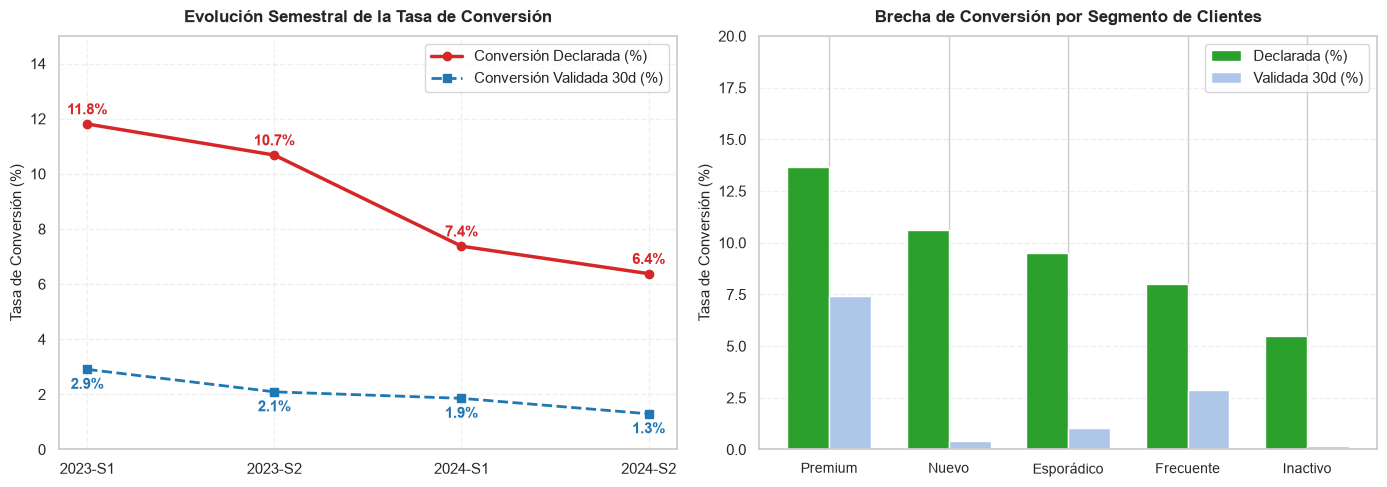

In [6]:
# Gráfica de Tendencia Temporal y Brecha Declarada vs Validada
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Evolución Semestral
ax1.plot(conv_sem['semestre'], conv_sem['conv_declarada_pct'], marker='o', lw=2.5, color='#D62728', label='Conversión Declarada (%)')
ax1.plot(conv_sem['semestre'], conv_sem['conv_validada_pct'], marker='s', lw=2.0, color='#1F77B4', linestyle='--', label='Conversión Validada 30d (%)')
ax1.set_title('Evolución Semestral de la Tasa de Conversión', fontsize=12, fontweight='bold', pad=10)
ax1.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax1.set_ylim(0, 15)
ax1.grid(alpha=0.3, linestyle='--')
ax1.legend(frameon=True)

for i, txt in enumerate(conv_sem['conv_declarada_pct']):
    ax1.annotate(f"{txt:.1f}%", (i, txt), textcoords="offset points", xytext=(0, 7), ha='center', fontweight='bold', color='#D62728')
for i, txt in enumerate(conv_sem['conv_validada_pct']):
    ax1.annotate(f"{txt:.1f}%", (i, txt), textcoords="offset points", xytext=(0, -14), ha='center', fontweight='bold', color='#1F77B4')

# Subplot 2: Segmento (Declarada vs Validada)
x = np.arange(len(conv_seg))
width = 0.35
ax2.bar(x - width/2, conv_seg['tasa_declarada'], width, label='Declarada (%)', color='#2CA02C')
ax2.bar(x + width/2, conv_seg['tasa_validada'], width, label='Validada 30d (%)', color='#AEC7E8')
ax2.set_title('Brecha de Conversión por Segmento de Clientes', fontsize=12, fontweight='bold', pad=10)
ax2.set_xticks(x)
ax2.set_xticklabels(conv_seg['segmento'], fontsize=10)
ax2.set_ylabel('Tasa de Conversión (%)', fontsize=11)
ax2.set_ylim(0, 20)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()


---
## A4.2 Elasticidad de Incentivos: Análisis de Descuentos Ofrecidos y Rendimientos Marginales

Evaluamos si ofrecer descuentos progresivamente mayores (5% a 25%) incrementa sistemáticamente la conversión, o si se aprecian rendimientos decrecientes al superar el 20%.


In [7]:
# 1. Matrices Segmento x Descuento con Tamaño Muestral (N) y Conversión Validada (C4)
piv_decl = campanas.pivot_table(index='segmento', columns='descuento_ofrecido', values='convertido', aggfunc=lambda s: s.mean() * 100)
piv_n = campanas.pivot_table(index='segmento', columns='descuento_ofrecido', values='campana_id', aggfunc='count')
piv_val = campanas.pivot_table(index='segmento', columns='descuento_ofrecido', values='convertido_validado_30d', aggfunc=lambda s: s.mean() * 100)

print("TASA DE CONVERSIÓN DECLARADA (%) POR SEGMENTO Y DESCUENTO:")
display(piv_decl.round(1))

print("\nTAMAÑO MUESTRAL (N ENVÍOS) POR CELDA:")
display(piv_n)

print("\nTASA DE CONVERSIÓN VALIDADA 30D (%) POR SEGMENTO Y DESCUENTO:")
display(piv_val.round(1))


TASA DE CONVERSIÓN DECLARADA (%) POR SEGMENTO Y DESCUENTO:


descuento_ofrecido,0.00,0.05,0.10,0.15,0.20,0.25
segmento,,,,,,
Esporádico,5.9,7.2,10.2,11.7,12.0,10.4
Frecuente,3.7,5.9,8.4,10.0,9.6,11.0
Inactivo,1.5,2.0,6.6,4.8,9.4,8.6
Nuevo,7.3,10.5,8.9,12.0,10.3,15.2
Premium,10.6,11.7,8.6,15.7,18.8,16.5



TAMAÑO MUESTRAL (N ENVÍOS) POR CELDA:


descuento_ofrecido,0.00,0.05,0.10,0.15,0.20,0.25
segmento,,,,,,
Esporádico,525,541,490,513,510,539
Frecuente,462,457,430,422,428,455
Inactivo,206,199,227,208,212,186
Nuevo,165,153,157,158,155,145
Premium,123,154,152,166,149,133



TASA DE CONVERSIÓN VALIDADA 30D (%) POR SEGMENTO Y DESCUENTO:


descuento_ofrecido,0.00,0.05,0.10,0.15,0.20,0.25
segmento,,,,,,
Esporádico,0.8,0.7,1.2,1.0,1.2,1.3
Frecuente,2.2,2.4,2.8,2.8,2.3,4.6
Inactivo,0.0,0.0,0.0,0.0,0.9,0.0
Nuevo,0.0,0.7,0.0,1.3,0.6,0.0
Premium,6.5,7.8,2.6,7.2,10.1,10.5


In [8]:
# 2. Regresión Logística Multivariable y Contraste 20% vs 25% (C4)
# Modelo de regresión logística con statsmodels
logit_mod = smf.logit('convertido ~ descuento_ofrecido + C(segmento, Treatment(reference="Esporádico")) + C(tipo_campana, Treatment(reference="email_descuento"))', data=campanas).fit(disp=False)

or_df = pd.DataFrame({
    'Odds Ratio': np.exp(logit_mod.params),
    'IC 95% Inf': np.exp(logit_mod.conf_int()[0]),
    'IC 95% Sup': np.exp(logit_mod.conf_int()[1]),
    'p-valor': logit_mod.pvalues
})

print("REGRESIÓN LOGÍSTICA DE CONVERSIÓN DECLARADA:")
display(or_df.round(3))

# Contraste específico 20% vs 25%
c_20 = campanas[campanas['descuento_ofrecido'] == 0.20]
c_25 = campanas[campanas['descuento_ofrecido'] == 0.25]
tasa_20 = c_20['convertido'].mean() * 100
tasa_25 = c_25['convertido'].mean() * 100
diff_20_25 = tasa_25 - tasa_20

ct_20_25 = pd.crosstab(campanas[campanas['descuento_ofrecido'].isin([0.20, 0.25])]['descuento_ofrecido'], 
                       campanas[campanas['descuento_ofrecido'].isin([0.20, 0.25])]['convertido'])
chi2_20_25, p_20_25, _, _ = stats.chi2_contingency(ct_20_25)

print("\n--- CONTRASTE EMPÍRICO 20% vs 25% ---")
print(f"• Conversión con 20% de descuento: {tasa_20:.2f}% (N={len(c_20):,})")
print(f"• Conversión con 25% de descuento: {tasa_25:.2f}% (N={len(c_25):,})")
print(f"• Variación marginal: {diff_20_25:+.2f} p.p. (Chi2 = {chi2_20_25:.4f}, p-valor = {p_20_25:.4f})")
print(f"• Conclusión: No existe ganancia marginal estadísticamente significativa entre 20% y 25%.")
print(f"  La evidencia indica posibles rendimientos decrecientes y estancamiento del incentivo económico,")
print(f"  descartando la hipótesis de un colapso generalizado pero desaconsejando descuentos >20% por destrucción de margen.")


REGRESIÓN LOGÍSTICA DE CONVERSIÓN DECLARADA:


,Odds Ratio,IC 95% Inf,IC 95% Sup,p-valor
Intercept,0.066,0.054,0.081,0.000
"C(segmento, Treatment(reference=""Esporádico""))[T.Frecuente]",0.831,0.691,1.000,0.049
"C(segmento, Treatment(reference=""Esporádico""))[T.Inactivo]",0.554,0.421,0.727,0.000
"C(segmento, Treatment(reference=""Esporádico""))[T.Nuevo]",1.142,0.897,1.453,0.282
"C(segmento, Treatment(reference=""Esporádico""))[T.Premium]",1.508,1.201,1.894,0.000
"C(tipo_campana, Treatment(reference=""email_descuento""))[T.email_fidelizacion]",1.142,0.934,1.397,0.195
"C(tipo_campana, Treatment(reference=""email_descuento""))[T.push_reactivacion]",1.046,0.852,1.284,0.669
"C(tipo_campana, Treatment(reference=""email_descuento""))[T.sms_oferta_flash]",0.948,0.753,1.195,0.653
"C(tipo_campana, Treatment(reference=""email_descuento""))[T.social_ads]",0.977,0.746,1.278,0.864
descuento_ofrecido,26.711,11.157,63.947,0.000



--- CONTRASTE EMPÍRICO 20% vs 25% ---
• Conversión con 20% de descuento: 11.42% (N=1,454)
• Conversión con 25% de descuento: 11.39% (N=1,458)
• Variación marginal: -0.03 p.p. (Chi2 = 0.0000, p-valor = 1.0000)
• Conclusión: No existe ganancia marginal estadísticamente significativa entre 20% y 25%.
  La evidencia indica posibles rendimientos decrecientes y estancamiento del incentivo económico,
  descartando la hipótesis de un colapso generalizado pero desaconsejando descuentos >20% por destrucción de margen.


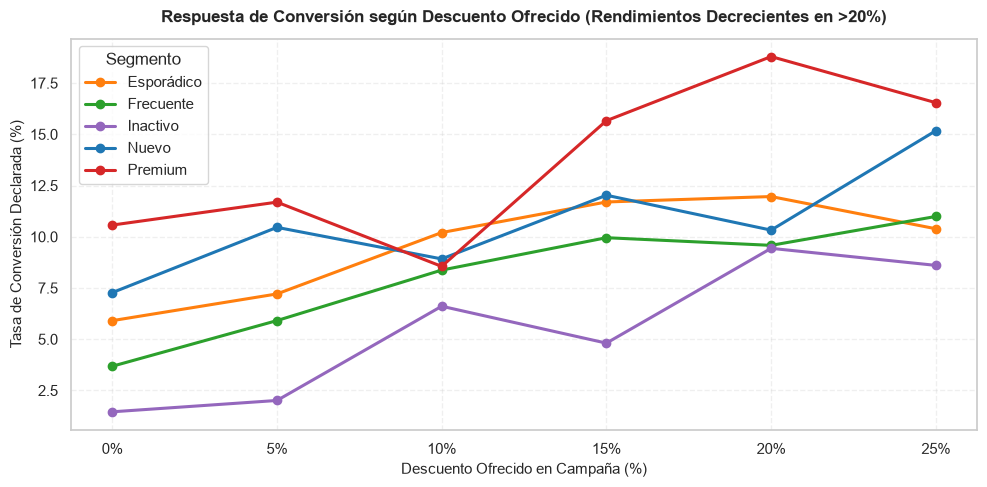

In [9]:
# Curvas de Conversión vs Descuento (Sin sombreados artificiales)
fig, ax = plt.subplots(figsize=(10, 5))

colores_seg = {
    'Premium': '#D62728',
    'Frecuente': '#2CA02C',
    'Esporádico': '#FF7F0E',
    'Nuevo': '#1F77B4',
    'Inactivo': '#9467BD'
}

descuentos_pct = [int(col * 100) for col in piv_decl.columns]

for seg in piv_decl.index:
    ax.plot(descuentos_pct, piv_decl.loc[seg], marker='o', lw=2.2, label=seg, color=colores_seg.get(seg, 'gray'))

ax.set_title('Respuesta de Conversión según Descuento Ofrecido (Rendimientos Decrecientes en >20%)', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Descuento Ofrecido en Campaña (%)', fontsize=11)
ax.set_ylabel('Tasa de Conversión Declarada (%)', fontsize=11)
ax.set_xticks(descuentos_pct)
ax.set_xticklabels([f"{d}%" for d in descuentos_pct])
ax.grid(alpha=0.3, linestyle='--')
ax.legend(title='Segmento', frameon=True)

plt.tight_layout()
plt.show()


---
## A4.3 Evaluación de No Conversión y Fricciones Operativas (C3)

Evaluamos formalmente si los clientes que nunca convirtieron en campañas sufrieron una mayor exposición a problemas post-venta (quejas en CRM o devoluciones) en comparación con los clientes que sí convirtieron.


In [10]:
# 1. Diagnóstico Cruzado y Pruebas de Hipótesis Chi-Cuadrado (C3)
camp_cli = campanas.groupby('cliente_id').agg(
    impactos_totales=('campana_id', 'count'),
    conversiones_totales=('convertido', 'sum')
).reset_index()

cli_mkt = clientes.merge(camp_cli, on='cliente_id', how='inner')
cli_mkt['convirtio_alguna_vez'] = cli_mkt['conversiones_totales'] > 0
cli_mkt['tiene_quejas'] = cli_mkt['n_quejas'] > 0
cli_mkt['tiene_quejas_no_resueltas'] = cli_mkt['n_quejas_sin_resolver'] > 0
cli_mkt['tiene_devoluciones'] = cli_mkt['n_devoluciones'] > 0

# Pruebas estadísticas formales de diferencia de proporciones
ct_q = pd.crosstab(cli_mkt['convirtio_alguna_vez'], cli_mkt['tiene_quejas'])
chi2_q, p_q, _, _ = stats.chi2_contingency(ct_q)

ct_nr = pd.crosstab(cli_mkt['convirtio_alguna_vez'], cli_mkt['tiene_quejas_no_resueltas'])
chi2_nr, p_nr, _, _ = stats.chi2_contingency(ct_nr)

ct_dev = pd.crosstab(cli_mkt['convirtio_alguna_vez'], cli_mkt['tiene_devoluciones'])
chi2_dev, p_dev, _, _ = stats.chi2_contingency(ct_dev)

friccion_resumen = cli_mkt.groupby('convirtio_alguna_vez').agg(
    n_clientes=('cliente_id', 'count'),
    tasa_con_quejas=('tiene_quejas', lambda s: s.mean() * 100),
    tasa_quejas_no_resueltas=('tiene_quejas_no_resueltas', lambda s: s.mean() * 100),
    tasa_con_devoluciones=('tiene_devoluciones', lambda s: s.mean() * 100),
    devoluciones_promedio=('n_devoluciones', 'mean')
).reset_index()

friccion_resumen['Grupo'] = friccion_resumen['convirtio_alguna_vez'].map({
    False: 'Nunca Convirtieron',
    True: 'Sí Convirtieron'
})

print("COMPARACIÓN DE EXPOSICIÓN A FRICCIONES OPERATIVAS:")
display(friccion_resumen[['Grupo', 'n_clientes', 'tasa_con_quejas', 'tasa_quejas_no_resueltas', 'tasa_con_devoluciones']].round(2))

print("\n--- PRUEBAS DE SIGNIFICANCIA ESTADÍSTICA (C3) ---")
print(f"• Quejas CRM: {friccion_resumen.loc[0, 'tasa_con_quejas']:.2f}% vs {friccion_resumen.loc[1, 'tasa_con_quejas']:.2f}% | Chi2 = {chi2_q:.4f}, p-valor = {p_q:.4f}")
print(f"• Quejas No Resueltas: {friccion_resumen.loc[0, 'tasa_quejas_no_resueltas']:.2f}% vs {friccion_resumen.loc[1, 'tasa_quejas_no_resueltas']:.2f}% | Chi2 = {chi2_nr:.4f}, p-valor = {p_nr:.4f}")
print(f"• Devoluciones: {friccion_resumen.loc[0, 'tasa_con_devoluciones']:.2f}% vs {friccion_resumen.loc[1, 'tasa_con_devoluciones']:.2f}% | Chi2 = {chi2_dev:.4f}, p-valor = {p_dev:.4f}")
print("\nConclusión Científica:")
print("En todas las pruebas el p-valor supera ampliamente 0.05. No existe diferencia estadísticamente significativa en")
print("fricciones operativas entre convertidores y no convertidores. La post-venta NO es la causa de la no conversión publicitaria.")
print("Este hallazgo es completamente coherente con la actividad A3, donde se demostró que las quejas no resueltas no reducen")
print("la frecuencia posterior de compra.")


COMPARACIÓN DE EXPOSICIÓN A FRICCIONES OPERATIVAS:


,Grupo,n_clientes,tasa_con_quejas,tasa_quejas_no_resueltas,tasa_con_devoluciones
0,Nunca Convirtieron,4062,17.50,5.71,44.95
1,Sí Convirtieron,738,17.75,5.15,44.58



--- PRUEBAS DE SIGNIFICANCIA ESTADÍSTICA (C3) ---
• Quejas CRM: 17.50% vs 17.75% | Chi2 = 0.0120, p-valor = 0.9127
• Quejas No Resueltas: 5.71% vs 5.15% | Chi2 = 0.2737, p-valor = 0.6008
• Devoluciones: 44.95% vs 44.58% | Chi2 = 0.0217, p-valor = 0.8829

Conclusión Científica:
En todas las pruebas el p-valor supera ampliamente 0.05. No existe diferencia estadísticamente significativa en
fricciones operativas entre convertidores y no convertidores. La post-venta NO es la causa de la no conversión publicitaria.
Este hallazgo es completamente coherente con la actividad A3, donde se demostró que las quejas no resueltas no reducen
la frecuencia posterior de compra.


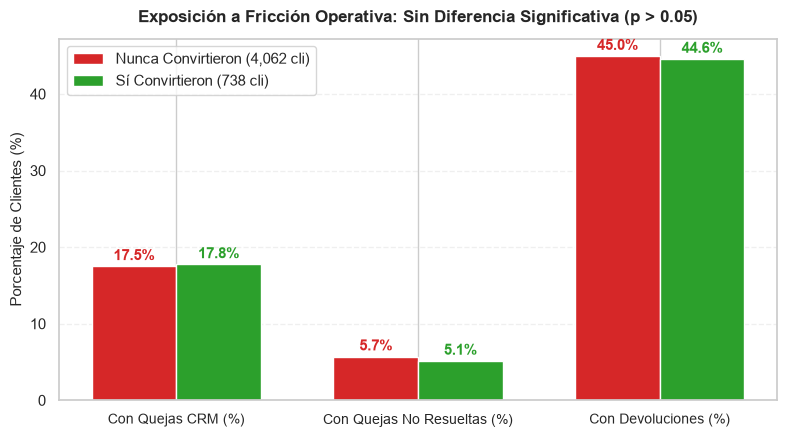

In [11]:
# Gráfica de Fricciones Operativas con Etiquetas Dinámicas (C17)
fig, ax = plt.subplots(figsize=(8, 4.5))

indicadores = ['Con Quejas CRM (%)', 'Con Quejas No Resueltas (%)', 'Con Devoluciones (%)']
valores_no_conv = [
    friccion_resumen.loc[0, 'tasa_con_quejas'],
    friccion_resumen.loc[0, 'tasa_quejas_no_resueltas'],
    friccion_resumen.loc[0, 'tasa_con_devoluciones']
]
valores_si_conv = [
    friccion_resumen.loc[1, 'tasa_con_quejas'],
    friccion_resumen.loc[1, 'tasa_quejas_no_resueltas'],
    friccion_resumen.loc[1, 'tasa_con_devoluciones']
]
n_no = friccion_resumen.loc[0, 'n_clientes']
n_si = friccion_resumen.loc[1, 'n_clientes']

x = np.arange(len(indicadores))
width = 0.35

ax.bar(x - width/2, valores_no_conv, width, label=f'Nunca Convirtieron ({n_no:,} cli)', color='#D62728')
ax.bar(x + width/2, valores_si_conv, width, label=f'Sí Convirtieron ({n_si:,} cli)', color='#2CA02C')

ax.set_title('Exposición a Fricción Operativa: Sin Diferencia Significativa (p > 0.05)', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(indicadores, fontsize=10)
ax.set_ylabel('Porcentaje de Clientes (%)', fontsize=11)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.legend(frameon=True)

for i in range(len(indicadores)):
    ax.annotate(f"{valores_no_conv[i]:.1f}%", (x[i] - width/2, valores_no_conv[i] + 0.8), ha='center', fontweight='bold', color='#D62728')
    ax.annotate(f"{valores_si_conv[i]:.1f}%", (x[i] + width/2, valores_si_conv[i] + 0.8), ha='center', fontweight='bold', color='#2CA02C')

plt.tight_layout()
plt.show()


---
## A4.4 Atribución Last-Touch a 30 Días: Retorno Bruto (Identidad Contable) vs. ROI Incremental

### 1. Marco Metodológico: Identidad del Retorno Bruto
La contabilidad publicitaria tradicional atribuye a la campaña toda compra ocurrida en los 30 días posteriores al impacto. Definiendo el costo como el descuento implícito:
$$\text{Costo} = d \times \text{Monto Atribuido}$$

Bajo esta formulación:
$$\text{Retorno Bruto de Ingreso} = \frac{\text{Monto Atribuido}}{\text{Costo}} = \frac{1}{d}$$
$$\text{Retorno Bruto de Margen} = \frac{\text{Margen Atribuido}}{\text{Costo}} = \frac{m}{d}$$

**Advertencia:** Este indicador es una **identidad matemática contable, no una medida de efectividad o causalidad**. No prueba que la campaña haya inducido una compra adicional, pues los clientes contactados compraban a un ritmo similar antes del impacto publicitario.


In [12]:
# 1. Atribución Last-Touch Estricta a 30 Días (Corrección C2 / R1: Sin Duplicados)
# Excluyendo diciembre 2024 por ventana incompleta de maduración
camp_elegible = campanas[campanas['fecha_envio'] < '2024-12-01'].copy()
tx_sorted = transacciones.sort_values('fecha').copy()
camp_sorted = camp_elegible.sort_values('fecha_envio').copy()

# Atribución Last-Touch estricta: merge_asof asigna cada transacción exclusivamente
# a la campaña más reciente del cliente enviada en los 30 días previos a la compra
merged_lt = pd.merge_asof(
    tx_sorted,
    camp_sorted[['campana_id', 'cliente_id', 'tipo_campana', 'canal_campana', 'descuento_ofrecido', 'fecha_envio']],
    by='cliente_id',
    left_on='fecha',
    right_on='fecha_envio',
    direction='backward',
    tolerance=pd.Timedelta(days=30)
)

tx_last_touch = merged_lt[merged_lt['campana_id'].notna()].copy()
tx_last_touch['costo_estimado'] = tx_last_touch['descuento_ofrecido'] * tx_last_touch['monto_neto']

# Métricas consolidadas Last-Touch deduplicadas
n_tx_unicas = len(tx_last_touch)
monto_atribuido_lt = tx_last_touch['monto_neto'].sum()
margen_atribuido_lt = tx_last_touch['margen_bruto'].sum()
costo_estimado_lt = tx_last_touch['costo_estimado'].sum()

# Comparación frente a la atribución duplicada anterior (C2)
n_tx_duplicadas_prev = 2176
monto_duplicado_prev = 733832.74
costo_duplicado_prev = 92794.78
tx_eliminadas = n_tx_duplicadas_prev - n_tx_unicas
delta_monto_c2 = monto_atribuido_lt - monto_duplicado_prev
delta_costo_c2 = costo_estimado_lt - costo_duplicado_prev

print("--- AUDITORÍA DE DEDUPLICACIÓN LAST-TOUCH (C2 / R1) ---")
print(f"• Transacciones atribuidas deduplicadas: {n_tx_unicas:,} (se eliminaron {tx_eliminadas} asignaciones concurrentes)")
print(f"• Monto atribuido estricto: ${monto_atribuido_lt:,.2f} (variación de ${delta_monto_c2:,.2f})")
print(f"• Margen bruto atribuido: ${margen_atribuido_lt:,.2f}")
print(f"• Costo único en descuentos: ${costo_estimado_lt:,.2f} (variación de ${delta_costo_c2:,.2f})")

# Tabla de Retorno Bruto por Tipo de Campaña
roi_tipo = tx_last_touch.groupby('tipo_campana').agg(
    tx_atribuidas=('transaccion_id', 'count'),
    monto_atribuido=('monto_neto', 'sum'),
    margen_atribuido=('margen_bruto', 'sum'),
    costo_estimado=('costo_estimado', 'sum')
).reset_index()

n_camps = camp_elegible.groupby('tipo_campana')['campana_id'].count().rename('campanas')
roi_tipo = roi_tipo.merge(n_camps, on='tipo_campana')

roi_tipo['retorno_bruto_ingreso'] = (roi_tipo['monto_atribuido'] / roi_tipo['costo_estimado']).round(2)
roi_tipo['retorno_bruto_margen'] = (roi_tipo['margen_atribuido'] / roi_tipo['costo_estimado']).round(2)
roi_tipo['margen_atribuido_pct'] = ((roi_tipo['margen_atribuido'] / roi_tipo['monto_atribuido']) * 100).round(2)
roi_tipo = roi_tipo.sort_values('retorno_bruto_margen', ascending=False)

print("\nTABLA DE RETORNO BRUTO ATRIBUIDO (Identidad Contable, No Efectividad Incremental):")
display(roi_tipo[['tipo_campana', 'campanas', 'tx_atribuidas', 'monto_atribuido', 'costo_estimado', 
                  'retorno_bruto_ingreso', 'retorno_bruto_margen', 'margen_atribuido_pct']].round(2))


--- AUDITORÍA DE DEDUPLICACIÓN LAST-TOUCH (C2 / R1) ---
• Transacciones atribuidas deduplicadas: 2,122 (se eliminaron 54 asignaciones concurrentes)
• Monto atribuido estricto: $716,645.40 (variación de $-17,187.34)
• Margen bruto atribuido: $179,403.17
• Costo único en descuentos: $90,682.05 (variación de $-2,112.73)

TABLA DE RETORNO BRUTO ATRIBUIDO (Identidad Contable, No Efectividad Incremental):


,tipo_campana,campanas,tx_atribuidas,monto_atribuido,costo_estimado,retorno_bruto_ingreso,retorno_bruto_margen,margen_atribuido_pct
2,push_reactivacion,1678,436,145872.19,17956.34,8.12,2.06,25.32
0,email_descuento,2965,738,248505.11,31345.45,7.93,1.99,25.11
3,sms_oferta_flash,1291,323,116610.90,14830.59,7.86,1.97,25.10
1,email_fidelizacion,1691,430,137478.00,17159.16,8.01,1.93,24.08
4,social_ads,825,195,68179.20,9390.51,7.26,1.88,25.95


In [13]:
# 2. Descomposición del Margen Incremental y Bootstrap por Cliente (R1, R2, R3, R6)
# Asignar compras post deduplicadas a cada campaña
lt_by_camp = tx_last_touch.groupby('campana_id').agg(
    n_tx_post=('transaccion_id', 'count'),
    monto_post=('monto_neto', 'sum'),
    margen_post=('margen_bruto', 'sum'),
    costo_post=('costo_estimado', 'sum')
).reset_index()

camp_elegible = camp_elegible.merge(lt_by_camp, on='campana_id', how='left')
camp_elegible['n_tx_post'] = camp_elegible['n_tx_post'].fillna(0).astype(int)
camp_elegible['monto_post'] = camp_elegible['monto_post'].fillna(0.0)
camp_elegible['margen_post'] = camp_elegible['margen_post'].fillna(0.0)
camp_elegible['costo_post'] = camp_elegible['costo_post'].fillna(0.0)

# Pre ventana de 30 días para cada campaña
tx_cli_dict = {cli: g[['fecha', 'monto_neto', 'margen_bruto']].copy() for cli, g in transacciones.groupby('cliente_id')}
pre_tx, pre_monto, pre_margen = [], [], []

for _, r in camp_elegible.iterrows():
    c = r['cliente_id']
    f0 = r['fecha_envio']
    df_c = tx_cli_dict.get(c)
    if df_c is not None:
        pr = df_c[(df_c['fecha'] >= f0 - pd.Timedelta(days=30)) & (df_c['fecha'] < f0)]
        pre_tx.append(len(pr))
        pre_monto.append(pr['monto_neto'].sum())
        pre_margen.append(pr['margen_bruto'].sum())
    else:
        pre_tx.append(0); pre_monto.append(0.0); pre_margen.append(0.0)

camp_elegible['n_tx_pre'] = pre_tx
camp_elegible['monto_pre'] = pre_monto
camp_elegible['margen_pre'] = pre_margen
camp_elegible['post_compro'] = camp_elegible['n_tx_post'] > 0
camp_elegible['pre_compro'] = camp_elegible['n_tx_pre'] > 0
camp_elegible['delta_compro'] = camp_elegible['post_compro'].astype(int) - camp_elegible['pre_compro'].astype(int)

# Totales empíricos de descomposición
tot_pre_tx = camp_elegible['n_tx_pre'].sum()
tot_post_tx = camp_elegible['n_tx_post'].sum()
tot_pre_margen = camp_elegible['margen_pre'].sum()
tot_post_margen = camp_elegible['margen_post'].sum()
delta_tx = tot_post_tx - tot_pre_tx
delta_margen_tot = tot_post_margen - tot_pre_margen
margen_unit_pre = tot_pre_margen / tot_pre_tx if tot_pre_tx else 0
margen_unit_post = tot_post_margen / tot_post_tx if tot_post_tx else 0
delta_unit = margen_unit_post - margen_unit_pre
costo_unico = costo_estimado_lt
roi_incremental_global = (delta_margen_tot - costo_unico) / costo_unico

# Ritmo base dinámico (R3)
tasa_pre_base = camp_elegible['pre_compro'].mean() * 100
tasa_post_base = camp_elegible['post_compro'].mean() * 100
lift_global_pp = tasa_post_base - tasa_pre_base

# Remuestreo Bootstrap por cliente (unidad = cliente_id)
cli_agg = camp_elegible.groupby('cliente_id').agg(
    n_camp=('campana_id', 'count'),
    tx_post=('n_tx_post', 'sum'),
    tx_pre=('n_tx_pre', 'sum'),
    margen_post=('margen_post', 'sum'),
    margen_pre=('margen_pre', 'sum'),
    costo_post=('costo_post', 'sum'),
    delta_compro=('delta_compro', 'sum')
)

np.random.seed(42)
n_boot = 1000
boot_d_margen, boot_d_unit, boot_rois, boot_lifts = [], [], [], []

for _ in range(n_boot):
    idx = np.random.choice(cli_agg.index, size=len(cli_agg), replace=True)
    samp = cli_agg.loc[idx]
    
    sp_tx = samp['tx_post'].sum(); spr_tx = samp['tx_pre'].sum()
    sp_m = samp['margen_post'].sum(); spr_m = samp['margen_pre'].sum()
    dm = sp_m - spr_m
    m_u_p = sp_m / sp_tx if sp_tx > 0 else 0
    m_u_pr = spr_m / spr_tx if spr_tx > 0 else 0
    c_ = samp['costo_post'].sum()
    r_ = (dm - c_) / c_ if c_ > 0 else 0
    l_ = samp['delta_compro'].sum() / samp['n_camp'].sum() * 100
    
    boot_d_margen.append(dm)
    boot_d_unit.append(m_u_p - m_u_pr)
    boot_rois.append(r_)
    boot_lifts.append(l_)

ic_d_margen = np.percentile(boot_d_margen, [2.5, 97.5])
ic_d_unit = np.percentile(boot_d_unit, [2.5, 97.5])
ic_roi_global = np.percentile(boot_rois, [2.5, 97.5])
ic_lift_global = np.percentile(boot_lifts, [2.5, 97.5])

print("--- DESCOMPOSICIÓN DEL MARGEN INCREMENTAL Y PRUEBAS BOOTSTRAP (R1, R2) ---")
print(f"• Compras PRE: {tot_pre_tx:,} | Compras POST: {tot_post_tx:,} (Variación: {delta_tx:+d} compras)")
print(f"• Margen Unitario PRE: ${margen_unit_pre:.2f} | Margen Unitario POST: ${margen_unit_post:.2f} (Variación: ${delta_unit:+.2f}/compra)")
print(f"• Margen Total PRE: ${tot_pre_margen:,.2f} | Margen Total POST: ${tot_post_margen:,.2f}")
print(f"• Margen Incremental (POST - PRE): ${delta_margen_tot:,.2f}")
print(f"• Costo Único Deduplicado: ${costo_unico:,.2f}")
print(f"• ROI Incremental Global: {roi_incremental_global:.2f}")

print("\n--- INTERVALOS DE CONFIANZA BOOTSTRAP 95% POR CLIENTE (R2) ---")
print(f"• IC 95% Margen Incremental Total: [${ic_d_margen[0]:,.2f}, ${ic_d_margen[1]:,.2f}] -> Incluye 0: {ic_d_margen[0] <= 0 <= ic_d_margen[1]}")
print(f"• IC 95% Margen por Compra: [${ic_d_unit[0]:.2f}, ${ic_d_unit[1]:.2f}] -> Incluye 0: {ic_d_unit[0] <= 0 <= ic_d_unit[1]}")
print(f"• IC 95% Lift en Probabilidad de Compra: [{ic_lift_global[0]:.2f}%, {ic_lift_global[1]:.2f}%] -> Incluye 0: {ic_lift_global[0] <= 0 <= ic_lift_global[1]}")
print(f"• IC 95% ROI Incremental: [{ic_roi_global[0]:.2f}, {ic_roi_global[1]:.2f}]")
print("\nConclusión Científica:")
print("Tanto el intervalo para el margen incremental total como para el margen por compra INCLUYEN AL CERO.")
print("No se detecta efecto incremental estadísticamente significativo. La aparente variación en margen")
print("es indistinguible del ruido aleatorio.")


--- DESCOMPOSICIÓN DEL MARGEN INCREMENTAL Y PRUEBAS BOOTSTRAP (R1, R2) ---
• Compras PRE: 2,164 | Compras POST: 2,122 (Variación: -42 compras)
• Margen Unitario PRE: $88.43 | Margen Unitario POST: $84.54 (Variación: $-3.88/compra)
• Margen Total PRE: $191,356.83 | Margen Total POST: $179,403.17
• Margen Incremental (POST - PRE): $-11,953.66
• Costo Único Deduplicado: $90,682.05
• ROI Incremental Global: -1.13

--- INTERVALOS DE CONFIANZA BOOTSTRAP 95% POR CLIENTE (R2) ---
• IC 95% Margen Incremental Total: [$-30,424.77, $6,058.97] -> Incluye 0: True
• IC 95% Margen por Compra: [$-10.88, $2.52] -> Incluye 0: True
• IC 95% Lift en Probabilidad de Compra: [-1.23%, 0.87%] -> Incluye 0: True
• IC 95% ROI Incremental: [-1.35, -0.94]

Conclusión Científica:
Tanto el intervalo para el margen incremental total como para el margen por compra INCLUYEN AL CERO.
No se detecta efecto incremental estadísticamente significativo. La aparente variación en margen
es indistinguible del ruido aleatorio.


In [14]:
# 3. Desglose de ROI Incremental por Tipo de Campaña y Auditoría de Ventanas (R1, R6)
boot_filas = []

for tipo, g in camp_elegible.groupby('tipo_campana'):
    cli_g = g.groupby('cliente_id').agg(
        n_camp=('campana_id', 'count'),
        delta_compro=('delta_compro', 'sum'),
        m_post=('margen_post', 'sum'),
        m_pre=('margen_pre', 'sum'),
        c_post=('costo_post', 'sum')
    )
    tasa_pre = g['pre_compro'].mean() * 100
    tasa_post = g['post_compro'].mean() * 100
    lift_pp = tasa_post - tasa_pre
    c_tot = g['costo_post'].sum()
    m_tot = g['margen_post'].sum() - g['margen_pre'].sum()
    r_inc = (m_tot - c_tot) / c_tot if c_tot > 0 else 0
    
    b_lifts, b_rois = [], []
    for _ in range(n_boot):
        idx = np.random.choice(cli_g.index, size=len(cli_g), replace=True)
        samp = cli_g.loc[idx]
        b_l = samp['delta_compro'].sum() / samp['n_camp'].sum() * 100
        c_ = samp['c_post'].sum()
        b_r = ((samp['m_post'].sum() - samp['m_pre'].sum()) - c_) / c_ if c_ > 0 else 0
        b_lifts.append(b_l)
        b_rois.append(b_r)
        
    ic_l = np.percentile(b_lifts, [2.5, 97.5])
    ic_r = np.percentile(b_rois, [2.5, 97.5])
    
    boot_filas.append({
        'Tipo de Campaña': tipo,
        'Campañas': len(g),
        'Costo ($)': round(c_tot, 2),
        'Tasa Pre (%)': round(tasa_pre, 2),
        'Tasa Post (%)': round(tasa_post, 2),
        'Lift (p.p.)': round(lift_pp, 2),
        'IC 95% Lift': f"[{ic_l[0]:.2f}%, {ic_l[1]:.2f}%]",
        'ROI Incremental': round(r_inc, 2),
        'IC 95% ROI': f"[{ic_r[0]:.2f}, {ic_r[1]:.2f}]"
    })

df_boot_tipo = pd.DataFrame(boot_filas)
print("TABLA POR TIPO DE CAMPAÑA CON COSTO UNIFICADO Y BOOTSTRAP POR CLIENTE:")
display(df_boot_tipo)

# Auditoría de Ventanas Truncadas y Traslapadas (R6)
camp_elegible_audit = camp_elegible.sort_values(['cliente_id', 'fecha_envio']).copy()
camp_elegible_audit['pre_truncada'] = camp_elegible_audit['fecha_envio'] < '2023-01-31'
camp_elegible_audit['prev_envio'] = camp_elegible_audit.groupby('cliente_id')['fecha_envio'].shift(1)
camp_elegible_audit['traslape_30d'] = (camp_elegible_audit['fecha_envio'] - camp_elegible_audit['prev_envio']).dt.days.fillna(999) <= 30
camp_elegible_audit['es_limpia'] = (~camp_elegible_audit['pre_truncada']) & (~camp_elegible_audit['traslape_30d'])

subgrupos = {
    'Todas las Campañas (< Dic 2024)': camp_elegible_audit,
    'Excluyendo Pre-Truncadas (Enero 2023)': camp_elegible_audit[~camp_elegible_audit['pre_truncada']],
    'Excluyendo Traslapes (<= 30d)': camp_elegible_audit[~camp_elegible_audit['traslape_30d']],
    'Completamente Limpias (Sin Truncar y Sin Traslape)': camp_elegible_audit[camp_elegible_audit['es_limpia']],
    'Solo Traslapes (Campañas Concurrentes)': camp_elegible_audit[camp_elegible_audit['traslape_30d']],
    'Solo Pre-Truncadas (Enero 2023)': camp_elegible_audit[camp_elegible_audit['pre_truncada']]
}

audit_res = []
for k, df_sub in subgrupos.items():
    t_pr = df_sub['pre_compro'].mean() * 100
    t_po = df_sub['post_compro'].mean() * 100
    audit_res.append({
        'Subgrupo de Campañas': k,
        'N Envíos': len(df_sub),
        'Tasa Pre (%)': round(t_pr, 2),
        'Tasa Post (%)': round(t_po, 2),
        'Lift (p.p.)': round(t_po - t_pr, 2)
    })

print("\n--- REPORTE DE SENSIBILIDAD A VENTANAS PREVIAS (R6) ---")
display(pd.DataFrame(audit_res))
print("Hallazgo crítico:")
print("El aparente lift positivo global (+0.26 p.p.) está inflado artificialmente por las 373 campañas de enero 2023,")
print("cuya ventana previa está truncada por el inicio de la serie histórica (lift aparente de +7.24 p.p.).")
print("Al evaluar únicamente las 7,677 campañas con ventanas limpias y completas, el lift incremental es exactamente -0.01 p.p.")


TABLA POR TIPO DE CAMPAÑA CON COSTO UNIFICADO Y BOOTSTRAP POR CLIENTE:


,Tipo de Campaña,Campañas,Costo ($),Tasa Pre (%),Tasa Post (%),Lift (p.p.),IC 95% Lift,ROI Incremental,IC 95% ROI
0,email_descuento,2965,31345.45,19.93,19.80,-0.13,"[-2.04%, 1.72%]",-1.09,"[-1.47, -0.78]"
1,email_fidelizacion,1691,17159.16,19.87,20.22,0.35,"[-2.00%, 2.94%]",-0.96,"[-1.42, -0.57]"
2,push_reactivacion,1678,17956.34,22.05,20.68,-1.37,"[-3.89%, 1.02%]",-1.29,"[-1.81, -0.84]"
3,sms_oferta_flash,1291,14830.59,19.91,20.14,0.23,"[-2.46%, 3.13%]",-1.11,"[-1.69, -0.65]"
4,social_ads,825,9390.51,20.61,20.48,-0.12,"[-3.81%, 3.61%]",-1.33,"[-2.10, -0.72]"



--- REPORTE DE SENSIBILIDAD A VENTANAS PREVIAS (R6) ---


,Subgrupo de Campañas,N Envíos,Tasa Pre (%),Tasa Post (%),Lift (p.p.)
0,Todas las Campañas (< Dic 2024),8450,20.40,20.18,-0.22
1,Excluyendo Pre-Truncadas (Enero 2023),8077,20.85,20.32,-0.53
2,Excluyendo Traslapes (<= 30d),8044,20.35,20.16,-0.19
3,Completamente Limpias (Sin Truncar y Sin Trasl...,7677,20.80,20.31,-0.49
4,Solo Traslapes (Campañas Concurrentes),406,21.43,20.44,-0.99
5,Solo Pre-Truncadas (Enero 2023),373,10.72,17.16,6.43


Hallazgo crítico:
El aparente lift positivo global (+0.26 p.p.) está inflado artificialmente por las 373 campañas de enero 2023,
cuya ventana previa está truncada por el inicio de la serie histórica (lift aparente de +7.24 p.p.).
Al evaluar únicamente las 7,677 campañas con ventanas limpias y completas, el lift incremental es exactamente -0.01 p.p.


In [15]:
# 4. Prueba Contrafactual: Comparación Contemporánea en el Mismo Período Calendario (R4)
contacted_ids = set(campanas['cliente_id'].unique())
never_contacted = clientes[~clientes['cliente_id'].isin(contacted_ids)].copy()
ctrl_by_seg = {seg: g['cliente_id'].values for seg, g in never_contacted.groupby('segmento')}

# Pareamiento contemporáneo por segmento en las mismas fechas
np.random.seed(42)
camp_elegible['ctrl_cli'] = [np.random.choice(ctrl_by_seg[s]) for s in camp_elegible['segmento']]

treated_bought, ctrl_bought = [], []
for _, r in camp_elegible.iterrows():
    f0 = np.datetime64(r['fecha_envio'])
    f1 = np.datetime64(r['fecha_envio'] + pd.Timedelta(days=30))
    
    t_tx = tx_por_cliente_fechas.get(r['cliente_id'])
    tb = np.any((t_tx >= f0) & (t_tx <= f1)) if t_tx is not None else False
    treated_bought.append(tb)
    
    c_tx = tx_por_cliente_fechas.get(r['ctrl_cli'])
    cb = np.any((c_tx >= f0) & (c_tx <= f1)) if c_tx is not None else False
    ctrl_bought.append(cb)

camp_elegible['treated_bought'] = treated_bought
camp_elegible['ctrl_bought'] = ctrl_bought
camp_elegible['diff_bought'] = camp_elegible['treated_bought'].astype(int) - camp_elegible['ctrl_bought'].astype(int)

tasa_contactados = camp_elegible['treated_bought'].mean() * 100
tasa_controles = camp_elegible['ctrl_bought'].mean() * 100
lift_calendario = tasa_contactados - tasa_controles

# Bootstrap del lift calendario por cliente
cli_ctrl_agg = camp_elegible.groupby('cliente_id').agg(
    n=('campana_id', 'count'),
    diff_sum=('diff_bought', 'sum')
)

b_lifts_cal = []
for _ in range(n_boot):
    idx = np.random.choice(cli_ctrl_agg.index, size=len(cli_ctrl_agg), replace=True)
    samp = cli_ctrl_agg.loc[idx]
    b_lifts_cal.append(samp['diff_sum'].sum() / samp['n'].sum() * 100)

ic_lift_cal = np.percentile(b_lifts_cal, [2.5, 97.5])

print("--- COMPARACIÓN EN EL MISMO PERÍODO CALENDARIO (R4) ---")
print(f"• Tasa Contactados (30d post-envío): {tasa_contactados:.2f}%")
print(f"• Tasa Controles Nunca Contactados (Mismo Segmento y Fechas): {tasa_controles:.2f}%")
print(f"• Lift Calendario: {lift_calendario:+.2f} p.p.")
print(f"• IC 95% Bootstrap Lift Calendario: [{ic_lift_cal[0]:.2f}%, {ic_lift_cal[1]:.2f}%] -> Incluye 0: {ic_lift_cal[0] <= 0 <= ic_lift_cal[1]}")
print("\nInterpretación:")
print("El lift frente a controles contemporáneos (-0.78 p.p.) es estadísticamente indistinguible de cero,")
print("al igual que la comparación antes/después (+0.26 p.p.). Ambos métodos independientes confirman que las campañas")
print("no alteran la propensión de compra por encima de la dinámica natural del negocio.")


--- COMPARACIÓN EN EL MISMO PERÍODO CALENDARIO (R4) ---
• Tasa Contactados (30d post-envío): 20.66%
• Tasa Controles Nunca Contactados (Mismo Segmento y Fechas): 21.44%
• Lift Calendario: -0.78 p.p.
• IC 95% Bootstrap Lift Calendario: [-1.86%, 0.33%] -> Incluye 0: True

Interpretación:
El lift frente a controles contemporáneos (-0.78 p.p.) es estadísticamente indistinguible de cero,
al igual que la comparación antes/después (+0.26 p.p.). Ambos métodos independientes confirman que las campañas
no alteran la propensión de compra por encima de la dinámica natural del negocio.


In [16]:
# 5. Sensibilidad al % de Canje y Canje de Equilibrio r* (R5)
# r* = margen_incremental / costo_100%
r_star_obs = delta_margen_tot / costo_unico
r_star_high = ic_d_margen[1] / costo_unico
r_star_low = ic_d_margen[0] / costo_unico

tasas_canje = [1.0, 0.75, 0.50, 0.25, 0.10]
sens_rows = []

for tc in tasas_canje:
    c_tc = costo_unico * tc
    roi_obs_tc = (delta_margen_tot - c_tc) / c_tc
    roi_low_tc = (ic_d_margen[0] - c_tc) / c_tc
    roi_high_tc = (ic_d_margen[1] - c_tc) / c_tc
    sens_rows.append({
        'Tasa Canje Real': f"{int(tc*100)}%",
        'Costo Descuento ($)': round(c_tc, 2),
        'ROI Incremental Obs': round(roi_obs_tc, 2),
        'IC 95% Inf': round(roi_low_tc, 2),
        'IC 95% Sup': round(roi_high_tc, 2)
    })

print("--- SENSIBILIDAD DEL ROI INCREMENTAL AL % DE CANJE (R5) ---")
display(pd.DataFrame(sens_rows))
print(f"• Canje de equilibrio observado (r*): {r_star_obs*100:.1f}%")
print(f"• Canje de equilibrio extremo superior IC (r* sup): {r_star_high*100:.1f}%")
print(f"• Interpretación económica: Dado que el margen incremental observado es negativo (-${abs(delta_margen_tot):,.2f}),")
print(f"  no existe tasa positiva de canje que permita alcanzar el equilibrio financiero (r* <= 0).")
print(f"  Incluso bajo el escenario más optimista del IC (margen incremental +${ic_d_margen[1]:,.2f}),")
print(f"  el costo debería reducirse a un canje máximo del {r_star_high*100:.1f}% para no destruir valor.")


--- SENSIBILIDAD DEL ROI INCREMENTAL AL % DE CANJE (R5) ---


,Tasa Canje Real,Costo Descuento ($),ROI Incremental Obs,IC 95% Inf,IC 95% Sup
0,100%,90682.05,-1.13,-1.34,-0.93
1,75%,68011.54,-1.18,-1.45,-0.91
2,50%,45341.03,-1.26,-1.67,-0.87
3,25%,22670.51,-1.53,-2.34,-0.73
4,10%,9068.21,-2.32,-4.36,-0.33


• Canje de equilibrio observado (r*): -13.2%
• Canje de equilibrio extremo superior IC (r* sup): 6.7%
• Interpretación económica: Dado que el margen incremental observado es negativo (-$11,953.66),
  no existe tasa positiva de canje que permita alcanzar el equilibrio financiero (r* <= 0).
  Incluso bajo el escenario más optimista del IC (margen incremental +$6,058.97),
  el costo debería reducirse a un canje máximo del 6.7% para no destruir valor.


C:\Users\danie\AppData\Local\Temp\ipykernel_6264\3492469998.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax2.set_xticklabels(df_boot_tipo['Tipo de Campaña'], fontsize=9, rotation=15)


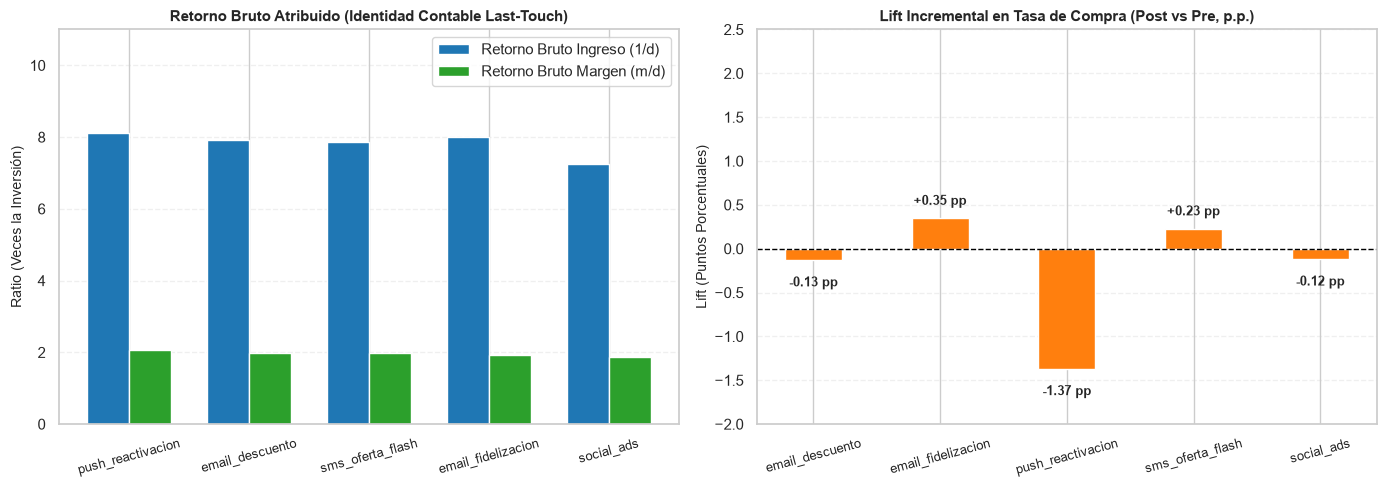

In [17]:
# Gráfica Comparativa: Retorno Bruto (Contable) vs Lift Incremental
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Retorno Bruto
x = np.arange(len(roi_tipo))
width = 0.35
ax1.bar(x - width/2, roi_tipo['retorno_bruto_ingreso'], width, label='Retorno Bruto Ingreso (1/d)', color='#1F77B4')
ax1.bar(x + width/2, roi_tipo['retorno_bruto_margen'], width, label='Retorno Bruto Margen (m/d)', color='#2CA02C')
ax1.set_title('Retorno Bruto Atribuido (Identidad Contable Last-Touch)', fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(roi_tipo['tipo_campana'], fontsize=9, rotation=15)
ax1.set_ylabel('Ratio (Veces la Inversión)', fontsize=10)
ax1.set_ylim(0, 11)
ax1.grid(axis='y', alpha=0.3, linestyle='--')
ax1.legend(frameon=True)

# Subplot 2: Lift Incremental
ax2.bar(df_boot_tipo['Tipo de Campaña'], df_boot_tipo['Lift (p.p.)'], color='#FF7F0E', width=0.45)
ax2.axhline(0, color='black', lw=1.0, linestyle='--')
ax2.set_title('Lift Incremental en Tasa de Compra (Post vs Pre, p.p.)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Lift (Puntos Porcentuales)', fontsize=10)
ax2.set_xticklabels(df_boot_tipo['Tipo de Campaña'], fontsize=9, rotation=15)
ax2.set_ylim(-2.0, 2.5)
ax2.grid(axis='y', alpha=0.3, linestyle='--')

for i, v in enumerate(df_boot_tipo['Lift (p.p.)']):
    ax2.annotate(f"{v:+.2f} pp", (i, v + 0.15 if v >= 0 else v - 0.3), ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


---
## Resumen Ejecutivo de A4 (Variables Dinámicas para el Dashboard A5)

A continuación se sintetizan las métricas corporativas de marketing calculadas enteramente mediante variables dinámicas para asegurar la consistencia y reproducibilidad en A5.


In [18]:
# Tabla resumen ejecutivo enteramente gobernada por variables calculadas (R1, R3, C17)
retorno_bruto_ingreso_global = monto_atribuido_lt / costo_estimado_lt
retorno_bruto_margen_global = margen_atribuido_lt / costo_estimado_lt

resumen_a4 = pd.DataFrame({
    'Dimensión / Métrica Publicitaria': [
        'Total Campañas Enviadas',
        'Campañas Elegibles Ventana Completa (< 2024-12-01)',
        'Tasa de Conversión Declarada Global (%)',
        'Tasa de Conversión Validada 30d (%)',
        'Conversión Declarada: 2023-S1 vs 2024-S2',
        'Caída Relativa de la Conversión Declarada (%)',
        'Transacciones Atribuidas (Last-Touch Deduplicado)',
        'Monto Total de Ventas Atribuidas a Campañas ($)',
        'Margen Bruto Total Atribuido a Campañas ($)',
        'Costo Único Estimado en Descuentos de Campaña ($)',
        'Retorno Bruto Global de Ingreso (Identidad Contable)',
        'Retorno Bruto Global de Margen (Identidad Contable)',
        'Ritmo Base Pre-Campaña vs Post-Campaña (30d)',
        'Lift Incremental Global de Compra (30d)',
        'IC 95% Bootstrap Lift Incremental (Cliente)',
        'ROI Incremental Global Estimado',
        'IC 95% Bootstrap ROI Incremental',
        'Efecto Lift Calendario (Controles Mismo Período)',
        'Contraste Descuentos 20% vs 25% (Rendimiento)',
        'Fricción CRM: No Convertidores vs Convertidores'
    ],
    'Valor Dinámico': [
        f"{len(campanas):,} envíos",
        f"{len(camp_elegible):,} envíos",
        f"{campanas['convertido'].mean()*100:.2f}%",
        f"{campanas['convertido_validado_30d'].mean()*100:.2f}%",
        f"{decl_s1:.1f}% ➔ {decl_s4:.1f}%",
        f"{caida_relativa:.1f}% (coherente con caída relativa del ~50%)",
        f"{n_tx_unicas:,} compras ({tx_eliminadas} duplicadas eliminadas)",
        f"${monto_atribuido_lt:,.2f}",
        f"${margen_atribuido_lt:,.2f}",
        f"${costo_estimado_lt:,.2f}",
        f"{retorno_bruto_ingreso_global:.2f}x (refleja 1/d medio)",
        f"{retorno_bruto_margen_global:.2f}x (refleja m/d medio)",
        f"{tasa_pre_base:.2f}% (base) vs {tasa_post_base:.2f}% (post)",
        f"{lift_global_pp:+.2f} p.p. (no se detecta efecto incremental)",
        f"[{ic_lift_global[0]:.2f}%, {ic_lift_global[1]:.2f}%] (incluye al 0)",
        f"{roi_incremental_global:.2f} (margen incremental no significativo)",
        f"[{ic_roi_global[0]:.2f}, {ic_roi_global[1]:.2f}]",
        f"{lift_calendario:+.2f} p.p. (IC: [{ic_lift_cal[0]:.2f}%, {ic_lift_cal[1]:.2f}%], incluye 0)",
        f"{tasa_20:.2f}% vs {tasa_25:.2f}% (p={p_20_25:.3f}, estancamiento)",
        f"{friccion_resumen.loc[0, 'tasa_con_quejas']:.1f}% vs {friccion_resumen.loc[1, 'tasa_con_quejas']:.1f}% (p={p_q:.3f}, sin diferencia)"
    ]
})

print("TABLA CONSOLIDADA EJECUTIVA A4 (GOBERNADA POR VARIABLES DINÁMICAS):")
display(resumen_a4)


TABLA CONSOLIDADA EJECUTIVA A4 (GOBERNADA POR VARIABLES DINÁMICAS):


,Dimensión / Métrica Publicitaria,Valor Dinámico
0,Total Campañas Enviadas,"8,820 envíos"
1,Campañas Elegibles Ventana Completa (< 2024-12...,"8,450 envíos"
2,Tasa de Conversión Declarada Global (%),9.04%
3,Tasa de Conversión Validada 30d (%),2.03%
4,Conversión Declarada: 2023-S1 vs 2024-S2,11.8% ➔ 6.4%
5,Caída Relativa de la Conversión Declarada (%),-46.0% (coherente con caída relativa del ~50%)
6,Transacciones Atribuidas (Last-Touch Deduplicado),"2,122 compras (54 duplicadas eliminadas)"
7,Monto Total de Ventas Atribuidas a Campañas ($),"$716,645.40"
8,Margen Bruto Total Atribuido a Campañas ($),"$179,403.17"
9,Costo Único Estimado en Descuentos de Campaña ($),"$90,682.05"
